# Transformer Encoder с нуля

Цель — обучить компактный Transformer без предобученных языковых
весов и сравнить его с TF-IDF baseline.

Архитектура:

`токены → embeddings + positions → Transformer Encoder → pooling → 77 классов`

In [2]:
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

DATA_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")

RANDOM_STATE = 42
MIN_FREQUENCY = 2
BATCH_SIZE = 32
EPOCHS = 8
PATIENCE = 2

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_ID = 0
UNK_ID = 1

MODEL_CONFIG = {
    "embedding_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "feedforward_dim": 256,
    "dropout": 0.10,
}

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

device = torch.device(
    "mps"
    if torch.backends.mps.is_available()
    else "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)

sys.path.insert(0, str(Path("../src").resolve()))

Device: cuda
Train: (7996, 2)
Validation: (2000, 2)


## Подготовка текста

Используется простой токенизатор. Словарь строится только по train,
редкие и неизвестные слова заменяются на `<UNK>`.

In [3]:
from banking_intent.scratch import build_vocabulary, tokenize

In [4]:
token_to_id = build_vocabulary(train_df["text"], min_frequency=MIN_FREQUENCY)

train_lengths = train_df["text"].map(lambda text: len(tokenize(text)))

length_95 = np.percentile(train_lengths, 95)
MAX_LENGTH = int(math.ceil(length_95 / 8) * 8)

categories = sorted(train_df["category"].unique())
label_to_id = {label: index for index, label in enumerate(categories)}
id_to_label = {index: label for label, index in label_to_id.items()}

print("Размер словаря:", len(token_to_id))
print("Количество классов:", len(label_to_id))
print("MAX_LENGTH:", MAX_LENGTH)

Размер словаря: 1381
Количество классов: 77
MAX_LENGTH: 32


## Dataset и DataLoader

In [5]:
from banking_intent.scratch import BankIntentDataset

train_dataset = BankIntentDataset(train_df, token_to_id, label_to_id, MAX_LENGTH)
val_dataset = BankIntentDataset(val_df, token_to_id, label_to_id, MAX_LENGTH)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
batch = next(iter(train_loader))
print("input_ids:", tuple(batch["input_ids"].shape))
print("attention_mask:", tuple(batch["attention_mask"].shape))
print("labels:", tuple(batch["label"].shape))

input_ids: (32, 32)
attention_mask: (32, 32)
labels: (32,)


## Модель

Маска не позволяет encoder учитывать `<PAD>`. После encoder
используется masked mean pooling по настоящим токенам.

In [6]:
from banking_intent.scratch import IntentTransformer

model = IntentTransformer(
    vocab_size=len(token_to_id),
    num_classes=len(label_to_id),
    max_length=MAX_LENGTH,
    **MODEL_CONFIG,
).to(device)
trainable_parameters = sum(
    (parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
)
print("Обучаемых параметров:", f"{trainable_parameters:,}")

Обучаемых параметров: 456,013


## Обучение

In [7]:
def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None,
) -> dict:
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = criterion(logits, labels)

        if is_training:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(all_labels, all_predictions, average="macro"),
    }


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

best_macro_f1 = -np.inf
best_state = None
epochs_without_improvement = 0
history = []

started_at = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics = run_epoch(model, val_loader, criterion)

    history.append(
        {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val macro F1 {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1 + 1e-4:
        best_macro_f1 = val_metrics["macro_f1"]
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping")
        break

training_seconds = time.perf_counter() - started_at

model.load_state_dict(best_state)
model.to(device)

history_df = pd.DataFrame(history)
display(history_df)

Epoch 01 | train loss 3.8797 | val loss 3.0638 | val macro F1 0.2688
Epoch 02 | train loss 2.4257 | val loss 1.9098 | val macro F1 0.5370
Epoch 03 | train loss 1.5954 | val loss 1.3853 | val macro F1 0.6605
Epoch 04 | train loss 1.1553 | val loss 1.0751 | val macro F1 0.7325
Epoch 05 | train loss 0.8773 | val loss 0.8842 | val macro F1 0.7749
Epoch 06 | train loss 0.6886 | val loss 0.7707 | val macro F1 0.8012
Epoch 07 | train loss 0.5542 | val loss 0.7033 | val macro F1 0.8123
Epoch 08 | train loss 0.4564 | val loss 0.6525 | val macro F1 0.8241


,epoch,train_loss,val_loss,train_macro_f1,val_macro_f1
0,1,3.879667,3.063803,0.100617,0.268824
1,2,2.425688,1.909755,0.415148,0.536957
2,3,1.595409,1.385313,0.606499,0.660488
3,4,1.155344,1.075113,0.719074,0.732531
4,5,0.877272,0.884206,0.788427,0.774930
5,6,0.688561,0.770724,0.830457,0.801232
6,7,0.554183,0.703290,0.861758,0.812253
7,8,0.456393,0.652451,0.884403,0.824073


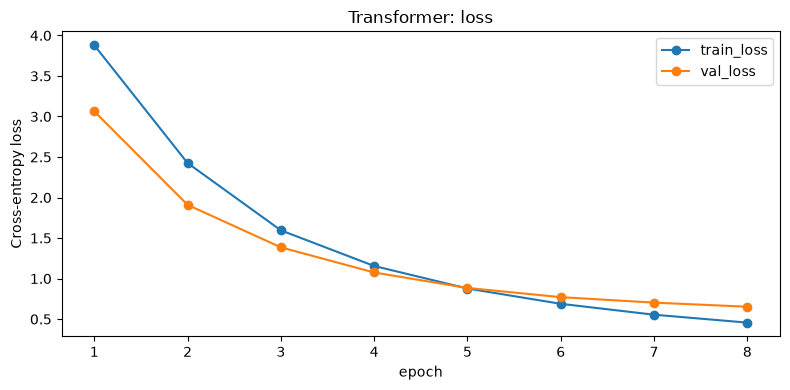

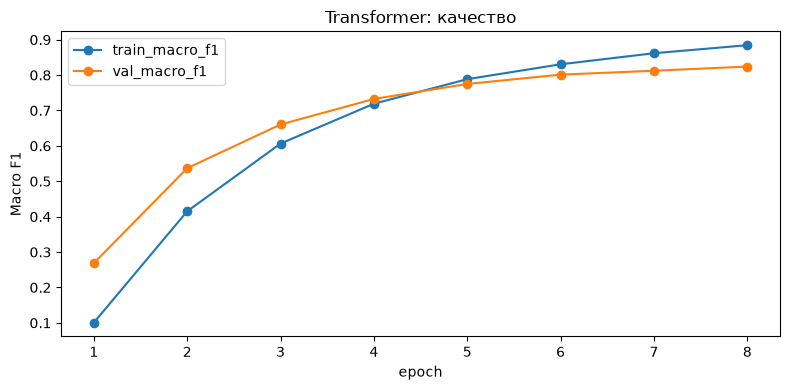

In [8]:
history_df.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", figsize=(8, 4))
plt.ylabel("Cross-entropy loss")
plt.title("Transformer: loss")
plt.tight_layout()
plt.show()

history_df.plot(
    x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o", figsize=(8, 4)
)
plt.ylabel("Macro F1")
plt.title("Transformer: качество")
plt.tight_layout()
plt.show()

## Validation и сохранение артефактов

In [9]:
@torch.no_grad()
def predict_loader(
    model: nn.Module, loader: DataLoader
) -> tuple[list[int], list[float]]:
    model.eval()

    predictions = []
    confidence = []

    for batch in loader:
        logits = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
        )

        probabilities = torch.softmax(logits, dim=1)
        batch_confidence, batch_predictions = probabilities.max(dim=1)

        predictions.extend(batch_predictions.cpu().tolist())
        confidence.extend(batch_confidence.cpu().tolist())

    return predictions, confidence


val_prediction_ids, val_confidence = predict_loader(model, val_loader)

val_predictions = [id_to_label[prediction_id] for prediction_id in val_prediction_ids]

val_accuracy = accuracy_score(val_df["category"], val_predictions)
val_macro_f1 = f1_score(val_df["category"], val_predictions, average="macro")

print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation macro F1: {val_macro_f1:.4f}")

validation_predictions = val_df.assign(
    predicted_category=val_predictions, confidence=val_confidence
)

display(
    validation_predictions.query("category != predicted_category").sample(
        n=min(
            12,
            (
                validation_predictions["category"]
                != validation_predictions["predicted_category"]
            ).sum(),
        ),
        random_state=42,
    )[["text", "category", "predicted_category", "confidence"]]
)

Validation accuracy: 0.8235
Validation macro F1: 0.8241


,text,category,predicted_category,confidence
1265,I cannot try my PIN anymore.,pin_blocked,get_physical_card,0.472141
205,The wait for this transfer seems to be taking ...,pending_transfer,transfer_timing,0.345780
1225,Can you tell me exactly what fees I will expec...,order_physical_card,getting_spare_card,0.223952
1128,I'm still waiting on my identity verification.,unable_to_verify_identity,why_verify_identity,0.471493
279,My transfer's stuck on pending.,pending_transfer,pending_card_payment,0.748316
1048,Why was my card charged when topping off my ba...,topping_up_by_card,balance_not_updated_after_bank_transfer,0.433619
80,I make payments for my place abroad using this...,transfer_fee_charged,card_payment_fee_charged,0.545767
280,I sent a payment but it isn't showing up in th...,transfer_not_received_by_recipient,direct_debit_payment_not_recognised,0.293552
792,I've never been to that store. That's a fraud...,card_payment_not_recognised,cancel_transfer,0.138737
845,What are the disposable cards for?,get_disposable_virtual_card,disposable_card_limits,0.512514


In [10]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
(REPORTS_DIR / "predictions").mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), MODELS_DIR / "transformer_from_scratch.pt")

metadata = {
    "max_length": MAX_LENGTH,
    "min_frequency": MIN_FREQUENCY,
    "token_to_id": token_to_id,
    "label_to_id": label_to_id,
    "model_config": MODEL_CONFIG,
}

with open(MODELS_DIR / "transformer_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

validation_predictions.to_csv(
    REPORTS_DIR / "predictions" / "transformer_scratch_validation.csv", index=False
)
history_df.to_csv(REPORTS_DIR / "transformer_scratch_history.csv", index=False)

summary = {
    "model": "transformer_scratch",
    "validation_accuracy": val_accuracy,
    "validation_macro_f1": val_macro_f1,
    "training_seconds": training_seconds,
    "trainable_parameters": trainable_parameters,
}

with open(
    REPORTS_DIR / "transformer_scratch_summary.json", "w", encoding="utf-8"
) as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

## Вывод

Этот Transformer обучается полностью с нуля: и embeddings, и
self-attention начинают со случайных весов. Поэтому он уступил TF-IDF даже при более сложной архитектуре.


## Вывод

За восемь эпох validation macro F1 вырос до **0,8241**, но остался ниже TF-IDF (**0,8613**). Более сложная архитектура в этом запуске не помогла. Дальше проверю, изменится ли результат при использовании предобученных представлений текста.